KMeans elbow+silhouette; MiniBatchKMeans timing; hierarchical dendrograms; DBSCAN k-distance+epsilon; cluster profile table;
cluster_pipeline() function

Dataset Shape: (150, 4)


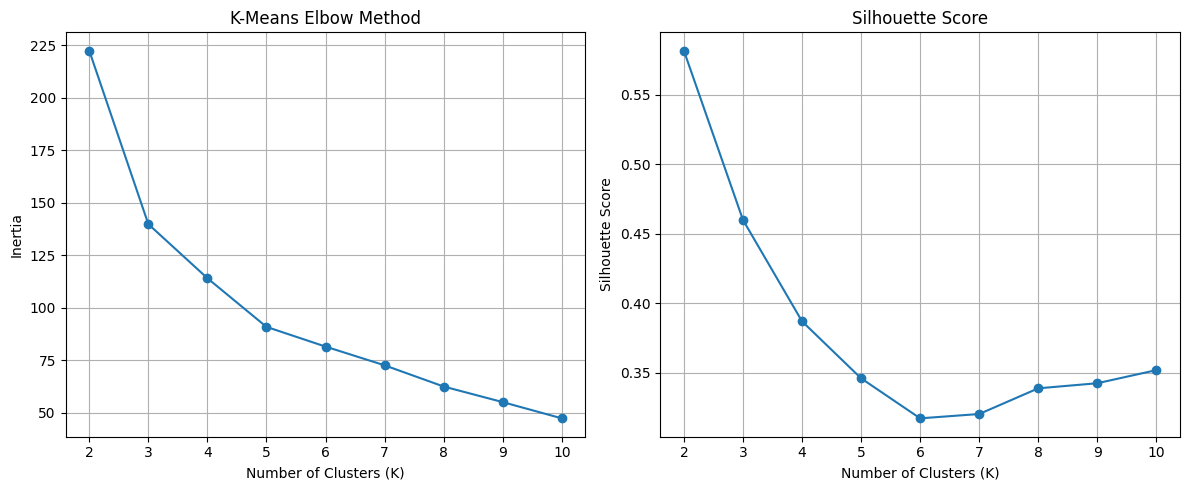

Best K: 2

KMeans time: 0.034424 seconds
MiniBatchKMeans time: 0.017545 seconds


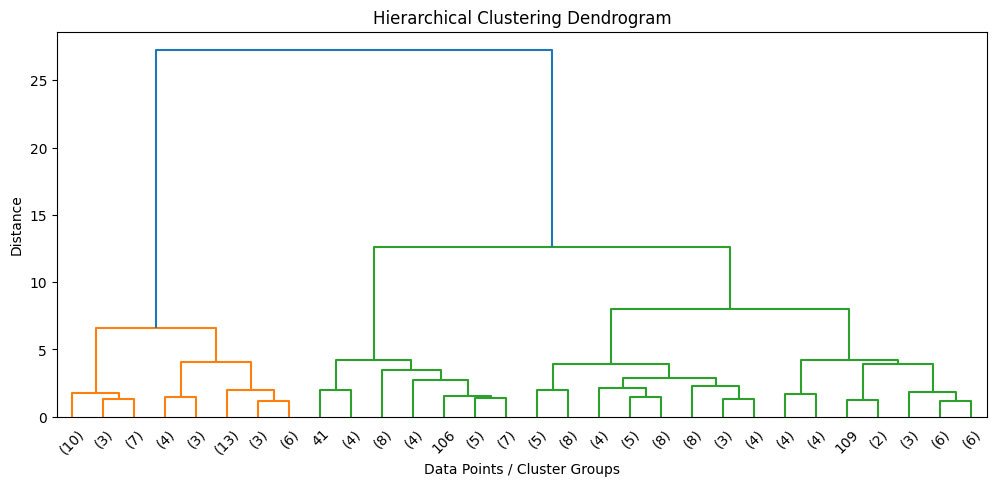

Hierarchical Silhouette Score: 0.4467


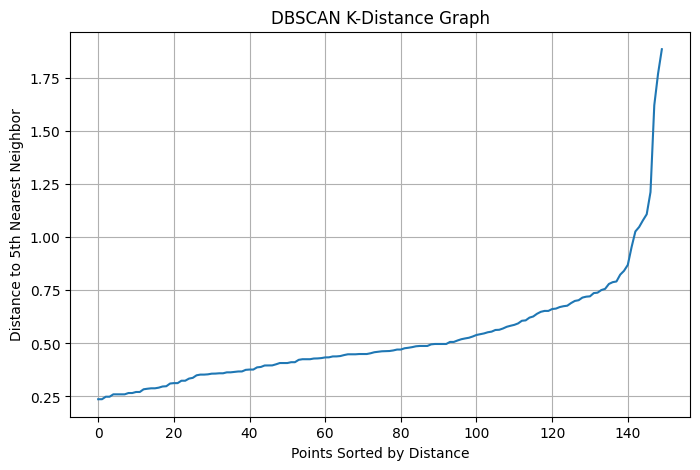


DBSCAN Epsilon: 0.8
Number of clusters: 2
Noise points: 4
DBSCAN Silhouette Score: 0.5979


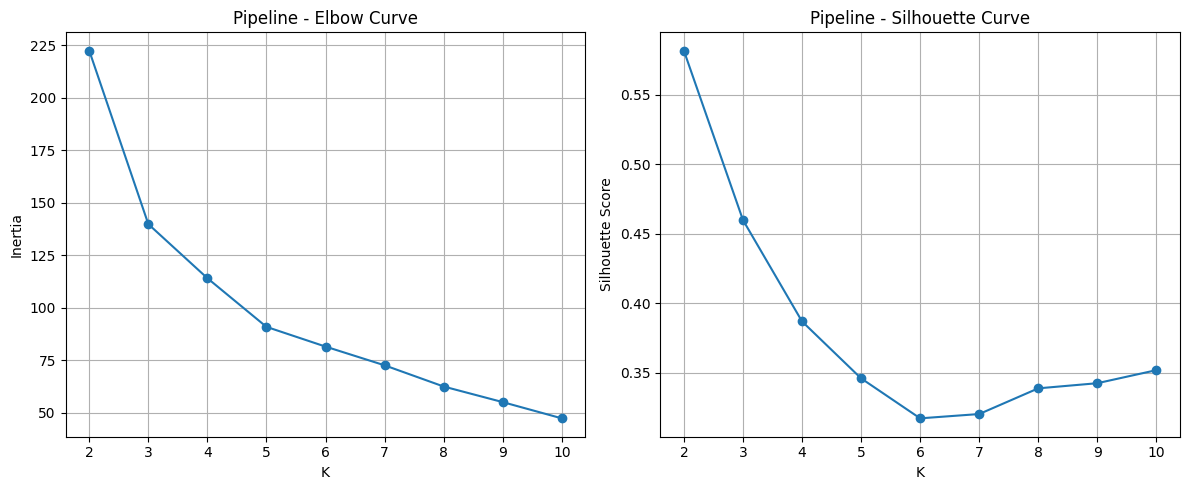


CLUSTER PIPELINE SUMMARY
 K  Inertia  Silhouette
 2  222.362      0.5818
 3  139.820      0.4599
 4  114.093      0.3869
 5   90.928      0.3459
 6   81.544      0.3171
 7   72.631      0.3202
 8   62.541      0.3387
 9   55.119      0.3424
10   47.391      0.3518

CLUSTER PROFILE TABLE
         sepal length (cm)  sepal width (cm)  petal length (cm)  \
Cluster                                                           
0                     5.80              2.67               4.37   
1                     5.01              3.43               1.46   
2                     6.78              3.10               5.51   

         petal width (cm)  
Cluster                    
0                    1.41  
1                    0.25  
2                    1.97  


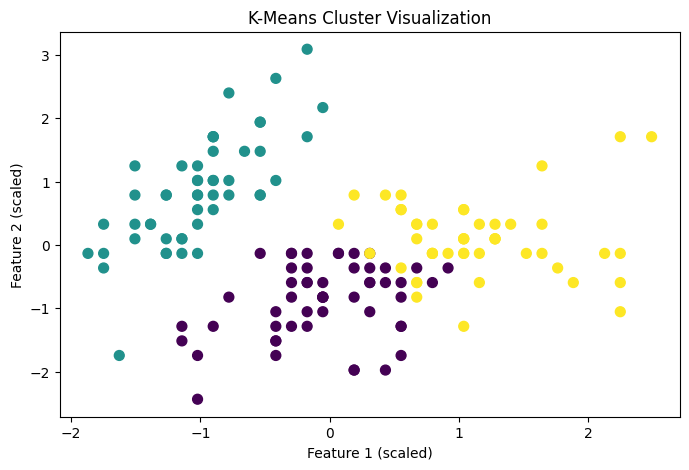


All clustering tasks completed successfully!


In [ ]:

# 1. IMPORT LIBRARIES
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, MiniBatchKMeans
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors
from scipy.cluster.hierarchy import linkage, dendrogram

# 2. LOAD AND SCALE DATA
iris = load_iris()
X = pd.DataFrame(iris.data, columns=iris.feature_names)
X_scaled = StandardScaler().fit_transform(X)

print("Dataset Shape:", X.shape)


# 3. KMEANS ELBOW + SILHOUETTE
k_values = range(2, 11)
inertia_values = []
silhouette_values = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)

    inertia_values.append(model.inertia_)
    silhouette_values.append(silhouette_score(X_scaled, labels))

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(list(k_values), inertia_values, marker='o')
plt.title("K-Means Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(list(k_values), silhouette_values, marker='o')
plt.title("Silhouette Score")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.grid()

plt.tight_layout()
plt.show()

best_k = list(k_values)[np.argmax(silhouette_values)]
print("Best K:", best_k)


# 4. MINIBATCH KMEANS TIMING
start = time.perf_counter()
KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_scaled)
kmeans_time = time.perf_counter() - start

start = time.perf_counter()
MiniBatchKMeans(
    n_clusters=3, random_state=42,
    batch_size=32, n_init=10
).fit(X_scaled)
minibatch_time = time.perf_counter() - start

print("\nKMeans time:", round(kmeans_time, 6), "seconds")
print("MiniBatchKMeans time:", round(minibatch_time, 6), "seconds")


# 5. HIERARCHICAL CLUSTERING DENDROGRAM
linked = linkage(X_scaled, method='ward')

plt.figure(figsize=(12, 5))
dendrogram(linked, truncate_mode='lastp', p=30)
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Data Points / Cluster Groups")
plt.ylabel("Distance")
plt.show()

hierarchical = AgglomerativeClustering(n_clusters=3)
hierarchical_labels = hierarchical.fit_predict(X_scaled)

print("Hierarchical Silhouette Score:",
      round(silhouette_score(X_scaled, hierarchical_labels), 4))


# 6. DBSCAN K-DISTANCE GRAPH + EPSILON
min_samples = 5

neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors.fit(X_scaled)
distances, _ = neighbors.kneighbors(X_scaled)

k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(8, 5))
plt.plot(k_distances)
plt.title("DBSCAN K-Distance Graph")
plt.xlabel("Points Sorted by Distance")
plt.ylabel("Distance to 5th Nearest Neighbor")
plt.grid()
plt.show()

# Adjust epsilon by observing the bend in the graph
eps_value = 0.8

dbscan = DBSCAN(eps=eps_value, min_samples=min_samples)
dbscan_labels = dbscan.fit_predict(X_scaled)

clusters = set(dbscan_labels) - {-1}
print("\nDBSCAN Epsilon:", eps_value)
print("Number of clusters:", len(clusters))
print("Noise points:", np.sum(dbscan_labels == -1))

# Silhouette only when at least two non-noise clusters exist
valid = dbscan_labels != -1
if len(set(dbscan_labels[valid])) >= 2:
    print("DBSCAN Silhouette Score:",
          round(silhouette_score(X_scaled[valid],
                                 dbscan_labels[valid]), 4))


# 7. CLUSTER PIPELINE FUNCTION
def cluster_pipeline(X_scaled, k_range):
    labels_array = []
    summary_rows = []

    for k in k_range:
        model = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=10
        )
        labels = model.fit_predict(X_scaled)
        labels_array.append(labels)

        summary_rows.append({
            "K": k,
            "Inertia": round(model.inertia_, 3),
            "Silhouette": round(
                silhouette_score(X_scaled, labels), 4
            )
        })

    summary_df = pd.DataFrame(summary_rows)

    # Plot evaluation curves
    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.plot(summary_df["K"], summary_df["Inertia"], marker='o')
    plt.title("Pipeline - Elbow Curve")
    plt.xlabel("K")
    plt.ylabel("Inertia")
    plt.grid()

    plt.subplot(1, 2, 2)
    plt.plot(summary_df["K"], summary_df["Silhouette"], marker='o')
    plt.title("Pipeline - Silhouette Curve")
    plt.xlabel("K")
    plt.ylabel("Silhouette Score")
    plt.grid()

    plt.tight_layout()
    plt.show()

    return labels_array, summary_df


labels_array, summary_df = cluster_pipeline(
    X_scaled, range(2, 11)
)

print("\nCLUSTER PIPELINE SUMMARY")
print(summary_df.to_string(index=False))


# 8. CLUSTER PROFILE TABLE
kmeans_model = KMeans(n_clusters=3, random_state=42, n_init=10)
profile_labels = kmeans_model.fit_predict(X_scaled)

profile_df = X.copy()
profile_df["Cluster"] = profile_labels

cluster_profile = profile_df.groupby("Cluster").mean().round(2)

print("\nCLUSTER PROFILE TABLE")
print(cluster_profile)


# 9. FINAL CLUSTER PLOT
plt.figure(figsize=(8, 5))
plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=profile_labels,
    cmap="viridis",
    s=50
)
plt.title("K-Means Cluster Visualization")
plt.xlabel("Feature 1 (scaled)")
plt.ylabel("Feature 2 (scaled)")
plt.show()

print("\nAll clustering tasks completed successfully!")


Write cluster_pipeline(X_scaled, k_range) — fits KMeans for each K, returns (labels_array, summary_DataFrame[K, inertia, silhouette]), plots
curves

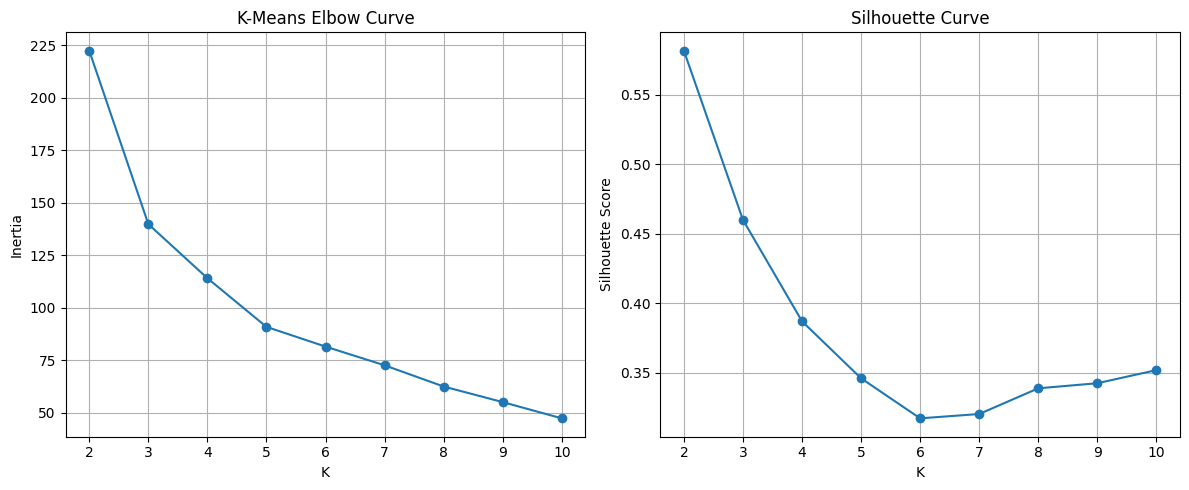

Summary DataFrame:
 K  inertia  silhouette
 2 222.3617      0.5818
 3 139.8205      0.4599
 4 114.0925      0.3869
 5  90.9275      0.3459
 6  81.5444      0.3171
 7  72.6311      0.3202
 8  62.5406      0.3387
 9  55.1195      0.3424
10  47.3910      0.3518

Number of K values evaluated: 9
Labels for K=2: [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0]


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler

def cluster_pipeline(X_scaled, k_range):
    labels_array = []
    summary = []

    for k in k_range:
        model = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=10
        )

        labels = model.fit_predict(X_scaled)
        labels_array.append(labels)

        inertia = model.inertia_
        silhouette = silhouette_score(X_scaled, labels)

        summary.append({
            "K": k,
            "inertia": inertia,
            "silhouette": silhouette
        })

    summary_DataFrame = pd.DataFrame(summary)

    # Plot inertia and silhouette curves
    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.plot(summary_DataFrame["K"],
             summary_DataFrame["inertia"], marker="o")
    plt.title("K-Means Elbow Curve")
    plt.xlabel("K")
    plt.ylabel("Inertia")
    plt.grid(True)

    plt.subplot(1, 2, 2)
    plt.plot(summary_DataFrame["K"],
             summary_DataFrame["silhouette"], marker="o")
    plt.title("Silhouette Curve")
    plt.xlabel("K")
    plt.ylabel("Silhouette Score")
    plt.grid(True)

    plt.tight_layout()
    plt.show()

    return labels_array, summary_DataFrame


# Example execution using the Iris dataset
iris = load_iris()
X_scaled = StandardScaler().fit_transform(iris.data)

labels_array, summary_DataFrame = cluster_pipeline(
    X_scaled, range(2, 11)
)

print("Summary DataFrame:")
print(summary_DataFrame.round(4).to_string(index=False))

print("\nNumber of K values evaluated:", len(labels_array))
print("Labels for K=2:", labels_array[0])
